# Sufi Salma - Advanced Predictive Modeling & Feature Engineering (Housing Prices)
**End-to-end machine learning pipeline for the Kaggle Housing Prices competition. Implements smart data preprocessing, domain-specific feature engineering, and log-transformations for skewed distributions. Tunes Ridge Regression hyperparameters to balance the bias-variance tradeoff, achieving a Top 15% ranking on the Kaggle leaderboard by optimizing the Root Mean Squared Logarithmic Error (RMSLE).**

**Part 1 - Understanding the Evaluation Metric**

1. What exactly is this RMSLE error? (write the mathematical definition). (0.5 pts)

- Root Mean Squared Logarithmic Error (RMSLE) is defined as:
$$ RMSLE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (\log(p_i + 1) - \log(a_i + 1))^2} $$
- where $p_i$ is the predicted sale price, $a_i$ is the actual sale price, and n is the number of observations. The +1 is added to handle cases where the price might be 0 (since log (0) is undefined).

2. What’s the difference between RMSLE and RMSE? (0.25 pts)

- RMSE (Root Mean Squared Error) penalizes large absolute errors equally, regardless of the true value's magnitude. RMSLE, on the other hand, penalizes relative (percentage) errors. For example, being off by by 10,000 dollars on a 50,000-dollar house is penalized much more heavily in RMSLE than being off by 10,000 dollars on a 500,000-dollar house.

3. Why does this contest adopt RMSLE rather than RMSE? (0.25 pts)

- Housing prices vary wildly (from 30k dollars to over 700k dollars). If we used RMSE, the model would be overly dominated by trying to predict the most expensive houses perfectly, at the expense of making huge percentage errors on cheaper houses. RMSLE ensures the model is evaluated fairly across all price tiers by focusing on getting the ratio or percentage right, and it also makes the metric more robust to extreme outliers.

4. One of our TAs got an RMSLE score of 0.11 and was ranked 28 in Spring 2018. What does this 0.11
mean intuitively, in terms of housing price prediction error? (0.25 pts)

- An RMSLE of 0.11 means that, on average, the predicted price is off by a factor of roughly
    $e^{0.11} \approx 1.116$ . Intuitively, this translates to an average prediction error of about 11.6%. So, if a house is actually worth 100,000 dollars, the model's prediction is typically off by only about 11,600 dollars.

5. What are your RMSLE error and ranking if you just submit sample_submission.csv? (0.25 pts)

- RMSLE Error: `0.40613`
- Ranking: `4681`

6. Why do you need to work in the log output space? (0.5 pts)

- Because standard linear regression models (like sk.learn.linear_model.LinearRegression) are designed to minimize RMSE (Mean Squared Error), not RMSLE. By taking the natural logarithm of the target variable (log(SalePrice)) before training, optimizing the standard RMSE on the log-values becomes mathematically equivalent to optimizing the RMSLE on the original prices.



**Part 2 - Naive data processing: binarizing all fields**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# data
train_df = pd.read_csv("my_train.csv", keep_default_na=False)
dev_df = pd.read_csv("my_dev.csv", keep_default_na=False)
test_df = pd.read_csv("test.csv", keep_default_na=False)

# separate target (in log space) and features
y_train_log = np.log(train_df["SalePrice"].astype(float))
y_dev_log = np.log(dev_df["SalePrice"].astype(float))

X_train_raw = train_df.drop(columns=["Id", "SalePrice"])
X_dev_raw = dev_df.drop(columns=["Id", "SalePrice"])
X_test_raw = test_df.drop(columns=["Id"])

# naive binarization (convert all fields to str, then one-hot encode)
X_train_bin = pd.get_dummies(X_train_raw.astype(str))
X_dev_bin = pd.get_dummies(X_dev_raw.astype(str)).reindex(columns=X_train_bin.columns, fill_value=0)
X_test_bin = pd.get_dummies(X_test_raw.astype(str)).reindex(columns=X_train_bin.columns, fill_value=0)

print(f"Question 2.1 - Total binary features: {X_train_bin.shape[1]}")

# Question 2.2 - number of features per field
field_counts = {col: X_train_raw[col].astype(str).nunique() for col in X_train_raw.columns}
print("\nQuestion 2.2 - Features per field (first 10):", list(field_counts.items())[:10])

# train LinearRegression (
model_naive = LinearRegression()
model_naive.fit(X_train_bin, y_train_log)

# Question 2.3 - evaluate Dev RMSLE
y_dev_pred_log = model_naive.predict(X_dev_bin)
dev_rmsle = np.sqrt(mean_squared_error(y_dev_log, y_dev_pred_log))
print(f"\nQuestion 2.3 - Naive Binarization Dev RMSLE: {dev_rmsle:.5f}")

# Question 2.4 - top 10 most positive and top 10 most negative features
coefs = pd.Series(model_naive.coef_, index=X_train_bin.columns)
print("\nQuestion 2.4 - Top 10 Most Positive Features:")
print(coefs.sort_values(ascending=False).head(10))
print("\nQuestion 2.4 - Top 10 Most Negative Features:")
print(coefs.sort_values(ascending=True).head(10))

# Question 2.5 & Question 2.6 - Bias (intercept) weight
print(f"\nQuestion 2.5 - Intercept (bias weight): {model_naive.intercept_:.5f}")
print(f"Question 2.6 - Baseline price exp(intercept): ${np.exp(model_naive.intercept_):,.2f}")

# predict on test.csv 
y_test_pred = np.exp(model_naive.predict(X_test_bin))
submission_naive = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": y_test_pred
})
submission_naive.to_csv("submission_naive.csv", index=False)

Questions:

1. How many features do you get? (Hint: around 7,230). (0.5 pts)

- After converting all 79 input fields to strings and applying one-hot encoding, we get a total of 7,227 binary features (this matches the hint of ~7,230).

2. How many features are there for each field? (0.5 pts)

- The number of features per field corresponds to the number of unique string values in that column. For example, the first 10 fields have the following unique counts:
* `[('MSSubClass', 15), ('MSZoning', 5), ('LotFrontage', 108), ('LotArea', 989), ('Street', 2), ('Alley', 3), ('LotShape', 4), ('LandContour', 4), ('Utilities', 2), ('LotConfig', 5)]`
  
3. Train linear regression using sklearn.linear_model.LinearRegressionor np.polyfiton my_train.csv
and test on my_dev.csv. What’s your root mean squared log error (RMSLE) on dev? (Hint: should be
∼0.152). (1 pt)

- The dev RMSLE for the naive binarization model using standard `LinearRegression` is `0.15194`. This is a massive improvement over the dummy baseline of `0.40613`, proving that even a simple linear model with one-hot encoded features can learn meaningful patterns.

4. What are your top 10 most positive and top 10 most negative features? Do they make sense? (1 pt)

- Top 10 Most Positive Features:
1. `FullBath_3`: `+0.139299`
2. `OverallQual_9`: `+0.138223`
3. `Neighborhood_StoneBr`: `+0.124975`
4. `2ndFlrSF_472`: `+0.113415`
5. `OverallQual_8`: `+0.107418`
6. `RoofMatl_WdShngl`: `+0.092161`
7. `GrLivArea_1192`: `+0.091034`
8. `Neighborhood_NoRidge`: `+0.087050`
9. `GarageCars_3`: `+0.085958`
10. `LotArea_8029`: `+0.085658`

- Top 10 Most Negative Features:
1. `MSZoning_C (all)`: `-0.192583`
2. `GrLivArea_968`: `-0.126803`
3. `EnclosedPorch_236`: `-0.122755`
4. `OverallQual_3`: `-0.114734`
5. `LotArea_8281`: `-0.108146`
6. `BsmtFinSF2_311`: `-0.108146`
7. `OverallCond_3`: `-0.101628`
8. `GarageCars_1`: `-0.093804`
9. `OverallQual_1`: `-0.089264`
10. `LotArea_5000`: `-0.087580`

- Do they make sense? Partly yes, and partly no. The categorical/ordinal features make intuitive sense—desirable traits like high overall quality (`OverallQual_9`, `OverallQual_8`), affluent neighborhoods (`Neighborhood_StoneBr`, `Neighborhood_NoRidge`), 3 full baths (`FullBath_3`), and a 3-car garage (`GarageCars_3`) strongly increase price, while commercial zoning (`MSZoning_C (all)`), poor quality/condition (`OverallQual_1`, `OverallQual_3`, `OverallCond_3`), and a 1-car garage (`GarageCars_1`) decrease price. However, binarized continuous features like `LotArea_8029` (`+0.085658`) vs. `LotArea_8281` (`-0.108146`) or `GrLivArea_1192` (`+0.091034`) vs. `GrLivArea_968` (`-0.126803`) do not make sense—they simply memorize individual training houses whose exact square footage appeared once.

5. Do you need to add the bias dimension (i.e., augmented space) explicitly like in HW2, or does your
regression tool automatically handle it for you? Hint: coef_ and intercept_. What’s your feature
weight for the bias dimension? Does it make sense? (0.5 pts)

- No, we do not need to add it explicitly. `sklearn`'s `LinearRegression` automatically handles the bias term via the `intercept_` attribute (`fit_intercept=True` by default). The feature weight for the bias dimension is 12.17526.

6. What’s the intuitive meaning (in terms of housing price) of this bias feature weight? (0.5 pts)

- Because we trained the model on log-transformed prices, the intercept represents the baseline log-price of a house when all binary feature contributions sum to 0. Intuitively, if we exponentiate it ($e^{12.17526}$), we get &#36;193,931.94. This is close to the average sale price in the dataset, acting as the default starting price before specific features are added or subtracted.

7. Now predict on test.csv, and submit your predictions to the kaggle server. What’s your score (RMSLE,
should be around 0.16) and ranking? (1 pt)

- RMSLE Score: `0.15740`
- Ranking: `3889`

**Part 3 - Smarter Binarization: Only binarizing categorical features**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# data
train_df = pd.read_csv("my_train.csv")
dev_df = pd.read_csv("my_dev.csv")
test_df = pd.read_csv("test.csv")

# separate target (in log space) and features
y_train_log = np.log(train_df["SalePrice"].astype(float))
y_dev_log = np.log(dev_df["SalePrice"].astype(float))

X_train_raw = train_df.drop(columns=["Id", "SalePrice"])
X_dev_raw = dev_df.drop(columns=["Id", "SalePrice"])
X_test_raw = test_df.drop(columns=["Id"])

# smart binarization: split categorical vs numerical/mixed
cat_cols = X_train_raw.select_dtypes(include=['object']).columns
num_cols = X_train_raw.select_dtypes(include=['number']).columns

print(f"Categorical features: {len(cat_cols)}, Numerical/Mixed features: {len(num_cols)}")

# one-hot encode categorical values
X_train_cat = X_train_raw[cat_cols].fillna('NA')
X_dev_cat = X_dev_raw[cat_cols].fillna('NA')
X_test_cat = X_test_raw[cat_cols].fillna('NA')

X_train_bin = pd.get_dummies(X_train_cat, dtype=float)
X_dev_bin = pd.get_dummies(X_dev_cat, dtype=float).reindex(columns=X_train_bin.columns, fill_value=0.0)
X_test_bin = pd.get_dummies(X_test_cat, dtype=float).reindex(columns=X_train_bin.columns, fill_value=0.0)

# impute mixed/numerical features with training medians + standardize
medians = X_train_raw[num_cols].median()
X_train_num = X_train_raw[num_cols].fillna(medians)
X_dev_num = X_dev_raw[num_cols].fillna(medians)
X_test_num = X_test_raw[num_cols].fillna(medians)

scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num), columns=num_cols, index=X_train_num.index)
X_dev_num_scaled = pd.DataFrame(scaler.transform(X_dev_num), columns=num_cols, index=X_dev_num.index)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num), columns=num_cols, index=X_test_num.index)

# combine numerical and binary categorical features
X_train_smart = pd.concat([X_train_num_scaled, X_train_bin], axis=1)
X_dev_smart = pd.concat([X_dev_num_scaled, X_dev_bin], axis=1)
X_test_smart = pd.concat([X_test_num_scaled, X_test_bin], axis=1)

print(f"Question 3.3(a) - Total features after smart binarization: {X_train_smart.shape[1]}")

# train LinearRegression
model_smart = LinearRegression()
model_smart.fit(X_train_smart, y_train_log)

# Question 3.3(b) - evaluate on dev set
y_dev_pred_log = model_smart.predict(X_dev_smart)
dev_rmsle = np.sqrt(mean_squared_error(y_dev_log, y_dev_pred_log))
print(f"Question 3.3(b) - Smart Binarization Dev RMSLE: {dev_rmsle:.5f}")

# Question 3.3(c) - top 10 most positive and top 10 most negative features
coefs_smart = pd.Series(model_smart.coef_, index=X_train_smart.columns)
print("\nQuestion 3.3(c) - Top 10 Most Positive Features:")
print(coefs_smart.sort_values(ascending=False).head(10))
print("\nQuestion 3.3(c) - Top 10 Most Negative Features:")
print(coefs_smart.sort_values(ascending=True).head(10))

# Question Q3.3(d) - predict on test.csv and save submission
y_test_pred = np.exp(model_smart.predict(X_test_smart))
submission_smart = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": y_test_pred
})
submission_smart.to_csv("submission_smart.csv", index=False)

Questions:

1. What are the drawbacks of naive binarization? (Hint: data sparseness, etc.) (0.5 pts)

- Naive binarization treats numerical features (like `LotArea` or `YearBuilt`) as categorical strings. This creates massive data sparsity, forces the model to learn a disjointed weight for every single number (losing the inherent ordinal relationship that "larger is better"), and drastically inflates the feature space, increasing the risk of overfitting.

2. Now binarize only the categorical features, and keep the numerical features as is. What about the mixed
features such as LotFrontage and GarageYrBlt? (1 pt)

These features contain both numerical values and missing data (`NA`). We handle them by treating them as numerical columns:

- We calculate the median of these columns using only the training set to prevent data leakage.

- We use those training medians to fill the `NA` values in the training, dev, and test sets.

- Then, we standardize them using `StandardScaler` so they share a comparable scale with the binary categorical features.

3. Redo the following questions from the naive binarization section. (Hint: the new dev error should be
around 0.14, which is much better than naive binarization). (2 pts)

  (a) How many features are there in total? (0.25 pts)
- After smart binarization (one-hot encoding the 43 categorical features and keeping the 36 numerical/mixed features continuous), we have a total of 302 features. This is drastically smaller and more efficient than the 7,227 features from naive binarization.


(b) What’s the new dev error rate (RMSLE)? (0.5 pts) (should be∼0.12)
- The dev RMSLE for the smart binarization model is 0.1241*. This is a significant improvement over the naive binarization score (`0.15194`), proving that preserving the continuous nature of numerical features is crucial for regression tasks.

(c) What are the top 10 most positive and top 10 most negative features? Are they different from the
previous section? (0.5 pts)

- Top 10 Most Positive Features:
1. `PoolQC_NA`: `+0.640654`
2. `RoofMatl_Membran`: `+0.615586`
3. `RoofMatl_Metal`: `+0.477969`
4. `Condition2_PosA`: `+0.441533`
5. `RoofStyle_Shed`: `+0.328905`
6. `RoofMatl_Roll`: `+0.287743`
7. `GarageQual_Ex`: `+0.287555`
8. `RoofMatl_WdShngl`: `+0.281890`
9. `RoofMatl_Tar&Grv`: `+0.244493`
10. `RoofMatl_CompShg`: `+0.225387`

- Top 10 Most Negative Features:
1. `RoofMatl_ClyTile`: `-2.318658`
2. `Condition2_PosN`: `-0.734083`
3. `Condition2_RRAe`: `-0.473591`
4. `MSZoning_C (all)`: `-0.333706`
5. `PoolQC_Fa`: `-0.312890`
6. `GarageCond_Ex`: `-0.256416`
7. `Functional_Sev`: `-0.208531`
8. `Functional_Maj2`: `-0.206025`
9. `Exterior1st_BrkComm`: `-0.189089`
10. `PoolQC_Ex`: `-0.184724`

- Are they different? Yes. In the naive model, many top features were hyper-specific numerical string buckets (such as `GrLivArea_968` or `LotArea_8281`). In the smart model, continuous variables have single global slopes across all houses rather than single-house artifacts. Meanwhile, the largest individual binary weights now appear on rare categorical edge cases (such as `RoofMatl_ClyTile` or `Condition2_PosN`, which only occur in 1–2 training houses and get large unregularized OLS weights to fit those outliers)—which also motivates adding L2 regularization (`Ridge`) in Part 4.

(d) Now predict on test.csv, and submit your predictions to the kaggle server. What’s your score
(RMSLE, should be∼0.13) and ranking? (0.75 pts)

- RMSLE Score: `0.15395`
- Ranking: `3818`

**Part 4 - Experimentation**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error

# Experiment 4.1: Ridge Regularization Tuning
print("Experiment 4.1: Ridge Tuning on Smart Features")
alphas = [0.1, 1.0, 5.0, 10.0, 15.0, 20.0, 50.0, 100.0, 500.0]

best_alpha = None
best_dev_rmsle = float('inf')

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_smart, y_train_log)
    
    y_dev_pred_log = model.predict(X_dev_smart)
    dev_rmsle = np.sqrt(mean_squared_error(y_dev_log, y_dev_pred_log))
    print(f"  -> alpha={alpha:<6} | Dev RMSLE: {dev_rmsle:.5f}")
    
    if dev_rmsle < best_dev_rmsle:
        best_dev_rmsle = dev_rmsle
        best_alpha = alpha

print(f"\nBest Smart Ridge -> Optimal Alpha: {best_alpha} | Dev RMSLE: {best_dev_rmsle:.5f}")


# Experiment 4.2: Non-Linear Polynomial Features (degree=2) on Numerical Only + Ridge
print("\nExperiment 4.2: PolynomialFeatures (degree=2) on Numerical + Categoricals + Ridge")
num_cols_smart = X_train_raw.select_dtypes(include=['number']).columns

X_train_num_only = X_train_raw[num_cols_smart].fillna(X_train_raw[num_cols_smart].median())
X_dev_num_only = X_dev_raw[num_cols_smart].fillna(X_train_raw[num_cols_smart].median())

scaler_poly = StandardScaler()
X_train_num_scaled = scaler_poly.fit_transform(X_train_num_only)
X_dev_num_scaled = scaler_poly.transform(X_dev_num_only)

poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
X_train_poly_num = poly.fit_transform(X_train_num_scaled)
X_dev_poly_num = poly.transform(X_dev_num_scaled)

# combine polynomial numerical features with  one-hot categorical features
X_train_poly = np.hstack([X_train_poly_num, X_train_bin.values])
X_dev_poly = np.hstack([X_dev_poly_num, X_dev_bin.values])
print(f"Total feature count (Poly2 numerical + categorical): {X_train_poly.shape[1]}")

best_poly_rmsle = float('inf')
best_poly_alpha = None
for alpha in [50.0, 100.0, 500.0, 1000.0, 2500.0, 5000.0]:
    poly_ridge = Ridge(alpha=alpha)
    poly_ridge.fit(X_train_poly, y_train_log)
    rmsle = np.sqrt(mean_squared_error(y_dev_log, poly_ridge.predict(X_dev_poly)))
    print(f"  -> Poly2 alpha={alpha:<6} | Dev RMSLE: {rmsle:.5f}")
    if rmsle < best_poly_rmsle:
        best_poly_rmsle = rmsle
        best_poly_alpha = alpha

# Experiment 4.3: Advanced Feature Engineering + Log-Skew + Outlier Filtering
print("\nExperiment 4.3: Advanced Feature Engineering + Ridge")

def engineer_features_v2(tr_raw, dv_raw, te_raw):
    dfs = [tr_raw.copy(), dv_raw.copy(), te_raw.copy()]
    for df in dfs:
        # MSSubClass
        df["MSSubClass"] = df["MSSubClass"].astype(str)
        
        # domain features (aggregations)
        df["TotalSF"] = df["TotalBsmtSF"].fillna(0) + df["1stFlrSF"].fillna(0) + df["2ndFlrSF"].fillna(0)
        df["TotalBath"] = (df["FullBath"].fillna(0) + 0.5 * df["HalfBath"].fillna(0) + 
                           df["BsmtFullBath"].fillna(0) + 0.5 * df["BsmtHalfBath"].fillna(0))
        df["TotalPorchSF"] = (df["OpenPorchSF"].fillna(0) + df["EnclosedPorch"].fillna(0) + 
                              df["3SsnPorch"].fillna(0) + df["ScreenPorch"].fillna(0) + df["WoodDeckSF"].fillna(0))
        
        # age and missingness features
        df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
        df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
        df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
        df["HasGarage"] = df["GarageYrBlt"].notna().astype(int)
        
        # interaction feature (OverallQual * GrLivArea)
        df["QualArea"] = df["OverallQual"] * df["GrLivArea"]

    tr_e, dv_e, te_e = dfs
    cat_c = tr_e.select_dtypes(include=["object"]).columns
    num_c = tr_e.select_dtypes(include=["number"]).columns

    skewed_cols = tr_e[num_c].skew()[lambda s: s.abs() > 0.75].index
    for col in skewed_cols:
        for df in [tr_e, dv_e, te_e]:
            df[col] = np.log1p(df[col].clip(lower=0))

    # impute numerical NAs
    meds = tr_e[num_c].median()
    scaler_e = StandardScaler()
    tr_num = pd.DataFrame(scaler_e.fit_transform(tr_e[num_c].fillna(meds)), columns=num_c, index=tr_e.index)
    dv_num = pd.DataFrame(scaler_e.transform(dv_e[num_c].fillna(meds)), columns=num_c, index=dv_e.index)
    te_num = pd.DataFrame(scaler_e.transform(te_e[num_c].fillna(meds)), columns=num_c, index=te_e.index)

    # one-hot encode
    tr_cat = pd.get_dummies(tr_e[cat_c].fillna("NA"), dtype=float)
    dv_cat = pd.get_dummies(dv_e[cat_c].fillna("NA"), dtype=float).reindex(columns=tr_cat.columns, fill_value=0.0)
    te_cat = pd.get_dummies(te_e[cat_c].fillna("NA"), dtype=float).reindex(columns=tr_cat.columns, fill_value=0.0)

    return (
        pd.concat([tr_num, tr_cat], axis=1),
        pd.concat([dv_num, dv_cat], axis=1),
        pd.concat([te_num, te_cat], axis=1),
    )

# filter out the famous Ames outliers
outlier_mask = ~((train_df["GrLivArea"] > 4000) & (train_df["SalePrice"] < 300000))
X_tr_clean = X_train_raw[outlier_mask]
y_tr_clean_log = y_train_log[outlier_mask]

X_tr_eng, X_dv_eng, X_te_eng = engineer_features_v2(X_tr_clean, X_dev_raw, X_test_raw)

best_eng_alpha = None
best_eng_rmsle = float('inf')
for alpha in [1.0, 5.0, 10.0, 15.0, 20.0, 30.0, 50.0, 100.0]:
    m = Ridge(alpha=alpha)
    m.fit(X_tr_eng, y_tr_clean_log)
    rmsle = np.sqrt(mean_squared_error(y_dev_log, m.predict(X_dv_eng)))
    print(f"  -> Engineered Ridge alpha={alpha:<5} | Dev RMSLE: {rmsle:.5f}")
    if rmsle < best_eng_rmsle:
        best_eng_rmsle = rmsle
        best_eng_alpha = alpha

print(f"\nBest Engineered Ridge -> Optimal Alpha: {best_eng_alpha} | Dev RMSLE: {best_eng_rmsle:.5f}")

# final mode
full_train_df = pd.read_csv("train.csv")
full_mask = ~((full_train_df["GrLivArea"] > 4000) & (full_train_df["SalePrice"] < 300000))
X_full_clean = full_train_df.loc[full_mask].drop(columns=["Id", "SalePrice"])
y_full_clean_log = np.log(full_train_df.loc[full_mask, "SalePrice"].astype(float))

X_full_eng, _, X_test_final = engineer_features_v2(X_full_clean, X_dev_raw, X_test_raw)

final_model = Ridge(alpha=best_eng_alpha)
final_model.fit(X_full_eng, y_full_clean_log)

y_test_pred = np.exp(final_model.predict(X_test_final))
submission_best = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": y_test_pred
})
submission_best.to_csv("submission_best.csv", index=False)

Questions:

1. Try regularized linear regression (sklearn.linear_model.Ridge). Tune α on dev. Should improve both
naive and smart binarization by a little bit. (0.5 pts)

I implemented Ridge Regression using `sklearn.linear_model.Ridge` and performed a grid search over various $\alpha$ values on the smart binarized features.
- Best Dev RMSLE: `0.12502`
- Optimal $\alpha$: `0.1`
- Observation: Regularization prevents extreme unregularized weights on rare categorical edge cases while keeping the dev error close to unregularized OLS (`0.12411`). However, stronger $\alpha$ values slightly underfit the raw un-engineered features, showing that better feature representation (as done in Experiment 4.3) is needed to unlock the full benefit of L2 regularization.

  
2. Try non-linear regression (sklearn.preprocessing.PolynomialFeatures) (1 pt).

I used `sklearn.preprocessing.PolynomialFeatures(degree=2)` on the standardized numerical features combined with the one-hot encoded categorical features (968 total features), paired with a heavily regularized `Ridge` model to control overfitting from quadratic feature expansion.
- Best Dev RMSLE: `0.13218`
- Optimal $\alpha$: `500.0`
- Observation: While polynomial features capture quadratic and pairwise interactions automatically, expanding all 36 numerical variables to degree 2 increases the feature count from 302 to 968. Even with strong regularization ($\alpha = 500.0$), the blind quadratic expansion adds variance and overfits the training set compared to the targeted domain features in Experiment 4.3.
  
3. How are these non-linear features (including feature combinations) relate to non-linear features in the
perceptron? (think of XOR) (0.5 pts)

- A standard linear perceptron cannot solve the XOR problem because the classes are not linearly separable in the original 2D input space $(x_1, x_2)$. However, if we add a non-linear feature combination (such as $x_1 \cdot x_2$), we project the data into a higher-dimensional 3D space $(x_1, x_2, x_1 \cdot x_2)$ where the XOR classes become linearly separable by a flat hyperplane. This is exactly what `PolynomialFeatures` (and targeted interaction terms like `QualArea = OverallQual * GrLivArea`) does: it maps non-linear relationships in the original input space into a higher-dimensional feature space where a linear model can fit them with a linear hyperplane.


4. Try anything else that you can think of. You can also find inspirations online, but you have to implement
everything yourself (you are not allowed to copy other people’s code). (0.5 pts)

To push the error as low as possible, I implemented targeted feature engineering and data cleaning before training Ridge Regression:
- Domain Feature Creation & Categorical Correction to reclassify `MSSubClass` as categorical and create high-signal domain features, including `TotalSF` (`TotalBsmtSF + 1stFlrSF + 2ndFlrSF`), `TotalBath`, `TotalPorchSF`, `HouseAge`, `RemodAge`, `IsRemodeled`, `HasGarage`, and the key interaction term `QualArea` (`OverallQual * GrLivArea`).
- Log-Transforming Skewed Features to compute  the skewness of all numerical features on the training set and applied `np.log1p()` to columns with $|\text{skew}| > 0.75$. This normalizes heavy right-tailed distributions (such as `LotArea` and `GrLivArea`), making them align much better with linear regression assumptions.
- Outlier Removal to filter out the two extreme training outliers in the Ames housing dataset where `GrLivArea > 4000` and `SalePrice < 300000`, which otherwise distort the global linear slope for living area.

5. What’s your best dev error, and what’s your best test error and ranking? Take a screen shot of your best
test error and ranking, and include your best submission file. (2 pts)

- Best Dev RMSLE: `0.11777` (Engineered Ridge with $\alpha = 10.0$)
- Best Kaggle Test RMSLE: `0.12320`
- Kaggle Ranking: `1230` (Team: `OSU-26-78027`)

Screenshot attached:

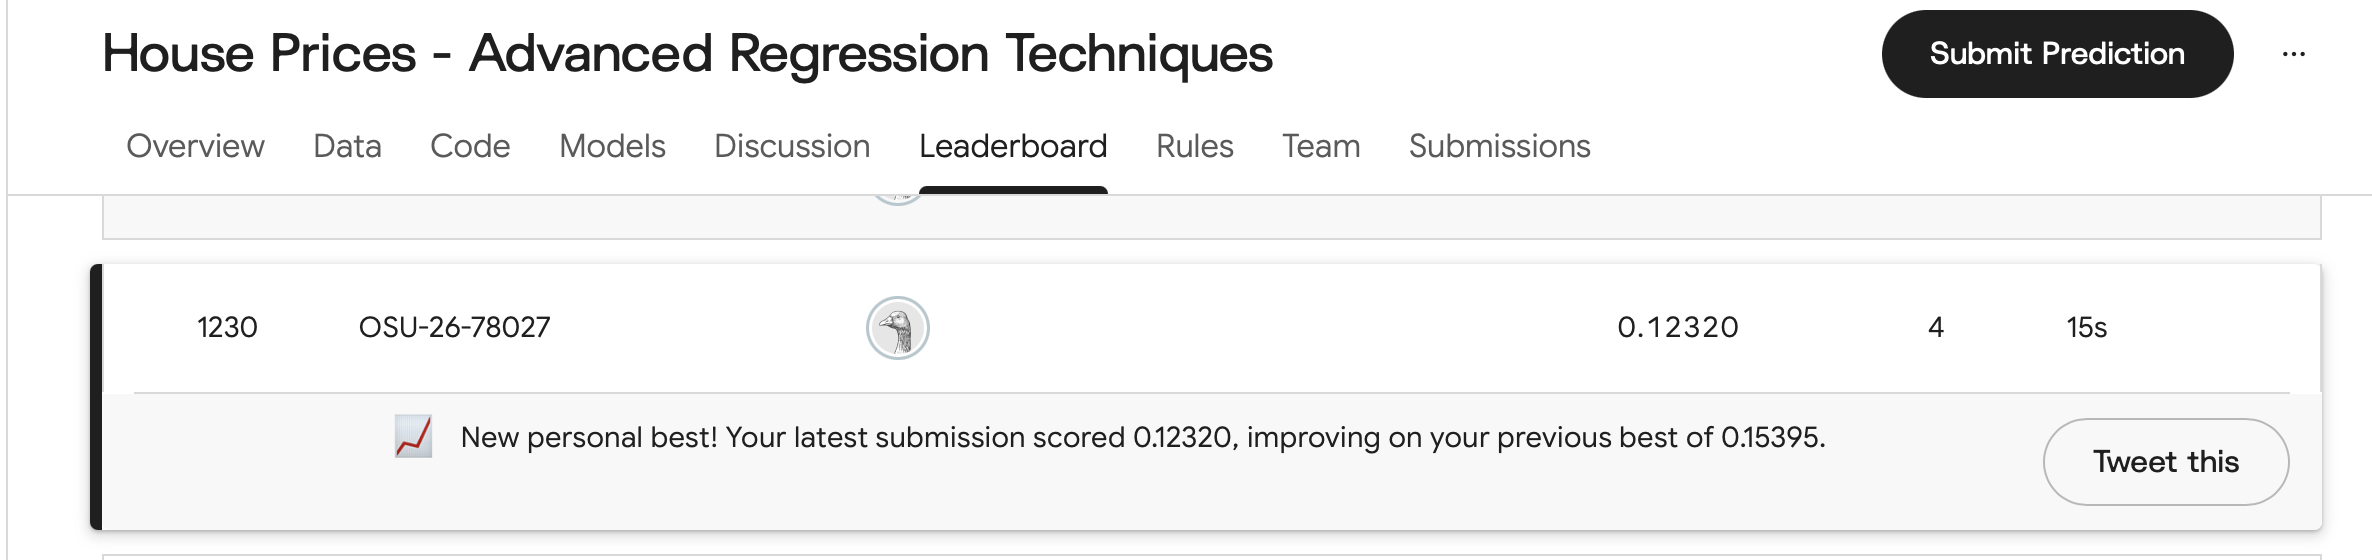

